# Practical 8: K-Means Clustering

*Teacher-demo version.* Cells marked **ORIGINAL** are your repository notebook, unchanged. Cells marked **ADDED** are new: input experiments with real outputs, viva questions and common errors. Original file: `Basic_KMeans_Clustering_Experiment.ipynb`

**A. Aim:** To apply K-Means clustering and evaluate the clusters using the Elbow Method and Silhouette Score.

**How to run (every practical)**

1. Install Python 3.10+ and Jupyter, then the libraries: `pip install numpy matplotlib scikit-learn jupyter`
2. Open a terminal / Anaconda Prompt in the folder containing this file and type `jupyter notebook`. Click this notebook.
3. Run cells one by one with **Shift + Enter** (or **Kernel -> Restart & Run All**). Run the cells in order - later cells need variables made by earlier ones.
4. To demonstrate a different result: edit the value on the line marked `# <-- CHANGED` in an experiment cell (or edit the same line in the original cell), then run that cell again. Run **Cell -> Run All** if later cells depend on it.
5. To print: **Ctrl + P** in the browser (as your lab readme suggests).

*Libraries needed here:* numpy, matplotlib, scikit-learn

---
## B / C. ORIGINAL PROGRAM AND ORIGINAL OUTPUT (unchanged cells follow)

<a href="https://colab.research.google.com/github/priyasathe123/ML-Practical-s/blob/main/Basic_KMeans_Clustering_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment: K-Means Clustering

**Author: Dr. Priya B. Pandharbale**

**Aim:** To apply K-Means clustering and evaluate the clusters using the Elbow Method and Silhouette Score.

**Libraries:** NumPy, Matplotlib and Scikit-learn

Run the following cells one by one.

## 1. Import libraries and create data

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Create simple sample data with 3 groups
X, y = make_blobs(n_samples=200, centers=3, random_state=42)

print("Dataset created successfully")
print("Number of samples:", len(X))

Dataset created successfully
Number of samples: 200


## 2. Display the dataset

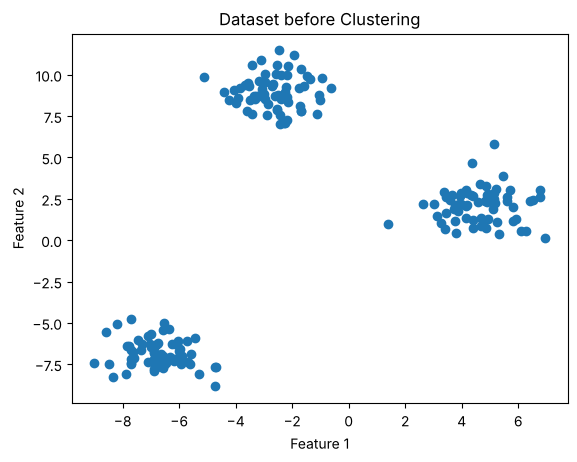

In [2]:
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Dataset before Clustering")
plt.show()

## 3. Find the number of clusters using the Elbow Method

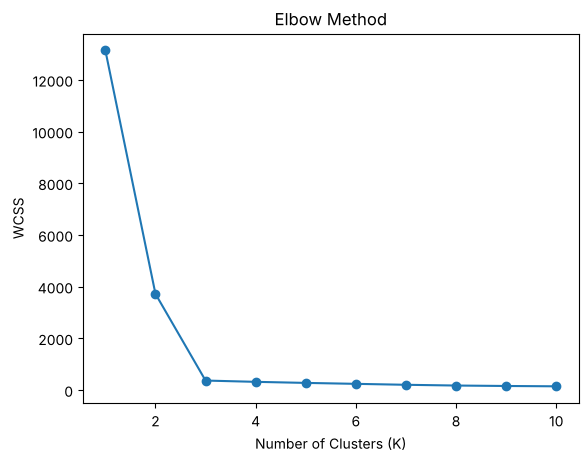

In [3]:
# Calculate WCSS for different numbers of clusters
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

# Plot the Elbow graph
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

**Observation:** WCSS decreases when the number of clusters increases. The suitable number of clusters is selected by looking for the point where the decrease starts becoming slower (the elbow). In this dataset, the elbow is expected around K = 3.

## 4. Apply K-Means with 3 clusters

In [4]:
# Create and train the K-Means model
model = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = model.fit_predict(X)

# Display cluster centres
print("Cluster Centres:")
print(model.cluster_centers_)

Cluster Centres:
[[-2.65882129  8.95756821]
 [-6.74539381 -6.85144337]
 [ 4.63218228  2.10121377]]


## 5. Visualize the clusters

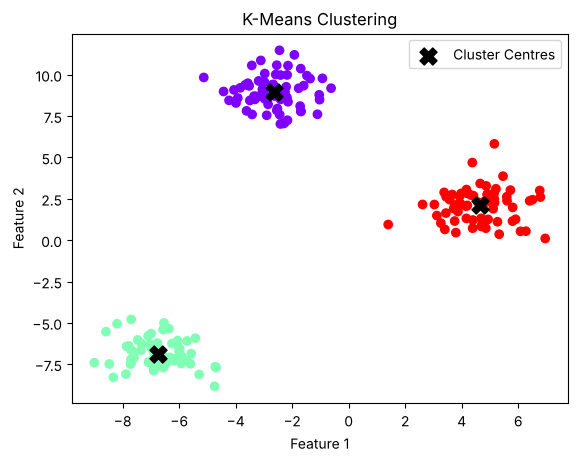

In [5]:
# Plot data points with their cluster labels
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="rainbow")

# Plot cluster centres
plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    color="black",
    marker="X",
    s=150,
    label="Cluster Centres"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.legend()
plt.show()

**Observation:** K-Means assigns each data point to the nearest cluster centre. Points with the same cluster label are shown in the same colour.

## 6. Evaluate using Silhouette Score

In [6]:
# Calculate Silhouette Score
score = silhouette_score(X, labels)

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.847


**Observation:** The Silhouette Score ranges from -1 to +1. A score closer to +1 indicates that clusters are well separated. A score near 0 indicates overlapping clusters, while a negative score may indicate that some points are assigned to unsuitable clusters.

## Result

K-Means clustering was successfully applied to the sample dataset. The Elbow Method was used to identify a suitable number of clusters, the clusters were visualized, and the Silhouette Score was calculated to evaluate cluster quality.

---
## D / E / F. INPUT EXPERIMENTS (ADDED)
Each experiment cell is **self-contained** (it re-creates what it needs), so you can run any experiment on its own. Lines ending in `# <-- CHANGED (original: ...)` show exactly what was edited; `# ADDED line` marks new helper lines.

### D. Input Experiment 1 - Use K = 4 on the same data

**Changed input:** `n_clusters=3` -> `4` in Step 4

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #4 (section *4. Apply K-Means with 3 clusters*).

Dataset created successfully
Number of samples: 200
Cluster Centres:
[[-6.74539381 -6.85144337]
 [ 3.87978917  1.83403686]
 [-2.65882129  8.95756821]
 [ 5.50592911  2.41148373]]


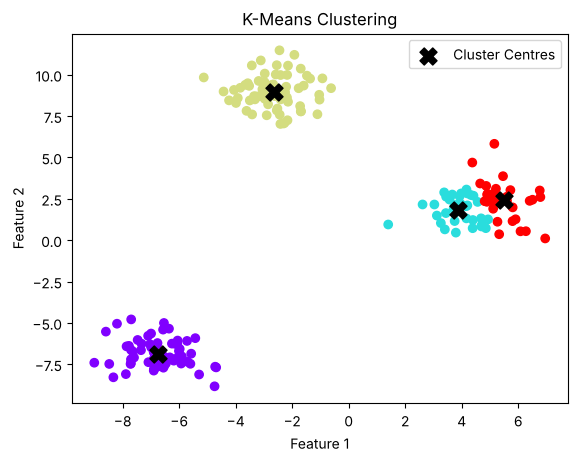

Silhouette Score: 0.68


In [7]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Create simple sample data with 3 groups
X, y = make_blobs(n_samples=200, centers=3, random_state=42)

print("Dataset created successfully")
print("Number of samples:", len(X))

# Create and train the K-Means model
model = KMeans(n_clusters=4, random_state=42, n_init=10)  # <-- CHANGED (original: model = KMeans(n_clusters=3, random_state=42, n_init=10))
labels = model.fit_predict(X)

# Display cluster centres
print("Cluster Centres:")
print(model.cluster_centers_)

# Plot data points with their cluster labels
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="rainbow")

# Plot cluster centres
plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    color="black",
    marker="X",
    s=150,
    label="Cluster Centres"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.legend()
plt.show()

# Calculate Silhouette Score
score = silhouette_score(X, labels)

print("Silhouette Score:", round(score, 3))

**Actual output explained**

**What changed:** `n_clusters = 4` on the same 3-group data. Silhouette score fell from 0.847 to **0.68**; there are now four centres (two lie inside the same original group, near (3.9, 1.8) and (5.5, 2.4)).

**Why:** K-Means is forced to split one natural cluster in two. Points in the split halves are close to the other half's centre, so separation drops. This is why the Silhouette Score is used to check K.

### E. Input Experiment 2 - Data with 4 groups, K = 4

**Changed input:** `centers=3` -> `4` in Step 1 and `n_clusters=3` -> `4` in Step 4

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #1 (section *1. Import libraries and create data*); code cell #4 (section *4. Apply K-Means with 3 clusters*).

Dataset created successfully
Number of samples: 200


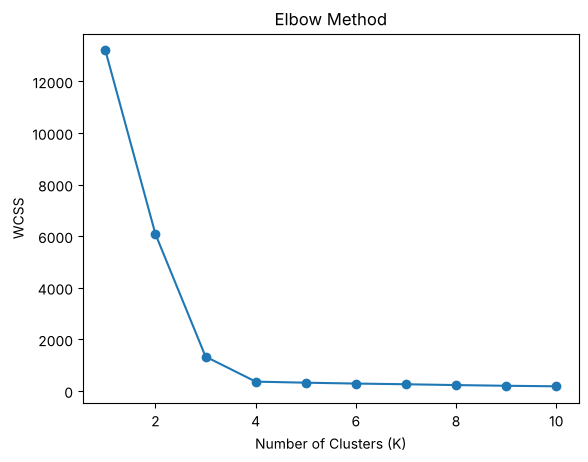

Cluster Centres:
[[ 4.58407676  2.1431444 ]
 [-2.70146566  8.90287872]
 [-6.75399588 -6.88944874]
 [-8.74950999  7.40771124]]


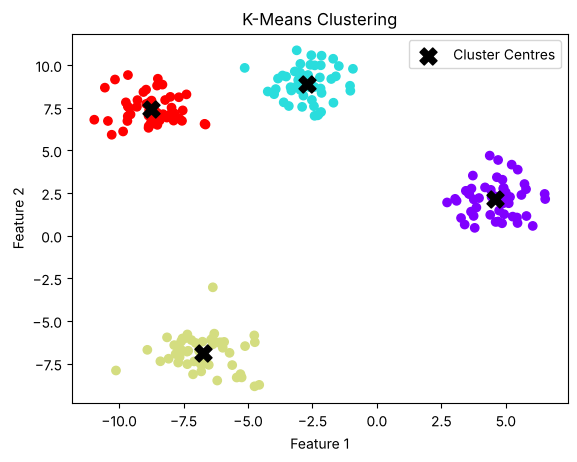

Silhouette Score: 0.795


In [8]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Create simple sample data with 3 groups
X, y = make_blobs(n_samples=200, centers=4, random_state=42)  # <-- CHANGED (original: X, y = make_blobs(n_samples=200, centers=3, random_state=42))

print("Dataset created successfully")
print("Number of samples:", len(X))

# Calculate WCSS for different numbers of clusters
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

# Plot the Elbow graph
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# Create and train the K-Means model
model = KMeans(n_clusters=4, random_state=42, n_init=10)  # <-- CHANGED (original: model = KMeans(n_clusters=3, random_state=42, n_init=10))
labels = model.fit_predict(X)

# Display cluster centres
print("Cluster Centres:")
print(model.cluster_centers_)

# Plot data points with their cluster labels
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="rainbow")

# Plot cluster centres
plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    color="black",
    marker="X",
    s=150,
    label="Cluster Centres"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.legend()
plt.show()

# Calculate Silhouette Score
score = silhouette_score(X, labels)

print("Silhouette Score:", round(score, 3))

**Actual output explained**

**What changed:** the data now have 4 groups (`centers=4`) and K = 4. Silhouette is **0.795**, and the elbow graph now bends at K = 4.

**Why:** K now matches the real structure, so the score is high again. It is a little below 0.847 because one of the four groups (around (-8.7, 7.4)) lies only about 6 units from its neighbour at (-2.7, 8.9), so the groups are less far apart than before.

### F. Input Experiment 3 - Overlapping groups

**Changed input:** `make_blobs(...)` -> add `cluster_std=3.0` (K stays 3)

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #1 (section *1. Import libraries and create data*).

Dataset created successfully
Number of samples: 200


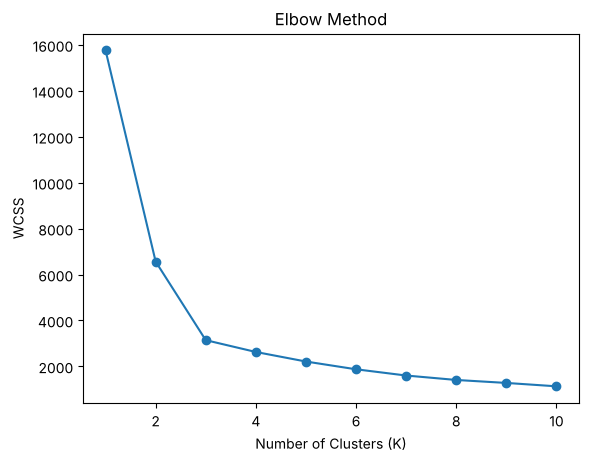

Cluster Centres:
[[ 4.70887772  2.15666024]
 [-6.45613594 -6.70912409]
 [-2.79204195  8.99137026]]


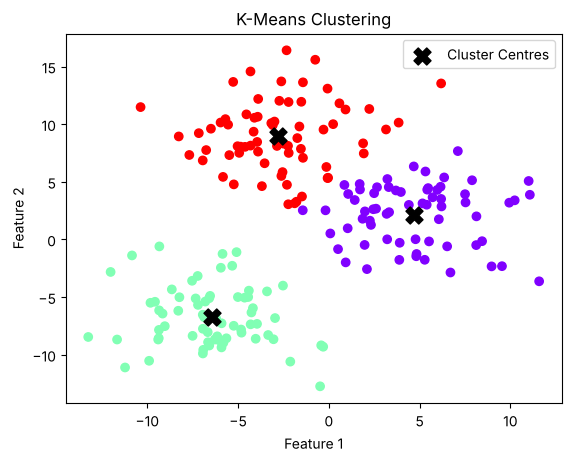

Silhouette Score: 0.56


In [9]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Create simple sample data with 3 groups
X, y = make_blobs(n_samples=200, centers=3, cluster_std=3.0, random_state=42)  # <-- CHANGED (original: X, y = make_blobs(n_samples=200, centers=3, random_state=42))

print("Dataset created successfully")
print("Number of samples:", len(X))

# Calculate WCSS for different numbers of clusters
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

# Plot the Elbow graph
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# Create and train the K-Means model
model = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = model.fit_predict(X)

# Display cluster centres
print("Cluster Centres:")
print(model.cluster_centers_)

# Plot data points with their cluster labels
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="rainbow")

# Plot cluster centres
plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    color="black",
    marker="X",
    s=150,
    label="Cluster Centres"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.legend()
plt.show()

# Calculate Silhouette Score
score = silhouette_score(X, labels)

print("Silhouette Score:", round(score, 3))

**Actual output explained**

**What changed:** `cluster_std = 3.0` spreads the three groups so they overlap (K stays 3). Silhouette fell to **0.56**; the centres moved only slightly.

**Why:** wider groups overlap, so many points are almost as close to a neighbouring centre as to their own. The elbow graph also becomes smoother and harder to read.

---
## G. IMPORTANT VIVA QUESTIONS AND ANSWERS (ADDED)

**Q1. Explain the K-Means algorithm.**  
1) Choose K initial centres. 2) Assign every point to the nearest centre. 3) Recompute each centre as the mean of its points. 4) Repeat 2-3 until assignments stop changing.

**Q2. What is WCSS / inertia and the elbow method?**  
WCSS is the sum of squared distances of points to their cluster centre. It always decreases as K grows; the 'elbow' is where the decrease slows sharply and suggests a good K.

**Q3. What is the Silhouette Score?**  
For each point s = (b - a)/max(a, b), where a = mean distance to its own cluster and b = mean distance to the nearest other cluster. Range -1 to +1; near +1 means well separated.

**Q4. Why `n_init=10` and `random_state=42`?**  
K-Means can get stuck in poor local minima, so it is run 10 times with different starting centres and the best is kept; `random_state` makes the result repeatable.

**Q5. Is K-Means supervised? Are the labels `y` used?**  
No, it is unsupervised. The labels from `make_blobs` are never passed to `fit`.

**Q6. What are the limitations of K-Means?**  
You must choose K; it assumes round, similar-sized clusters; it is sensitive to outliers and feature scale.

**Q7. Why did the silhouette drop for K = 4 in Experiment 1?**  
A natural cluster was split into two, so the two parts are close to each other and the separation shrinks.

---
## Common errors and solutions (ADDED)

- `FutureWarning` about `n_init` -> keep `n_init=10` as written in the notebook.
- Cluster colours/labels change between runs -> cluster numbers are arbitrary; only the grouping matters.
- `ValueError: n_samples=... should be >= n_clusters=...` -> K is larger than the number of data points.